# Evaluación en vivo: pronósticos emitidos en el corte frente a lo observado después

En este cuaderno medimos el desempeño de los modelos tal como operan, entrenados con todo lo anterior al corte del
modelado (`config.FIN_MODELADO`) y aplicados **sin reentrenar** a los días posteriores, que ningún modelo ni
pronóstico meteorológico conocía. Es la evaluación más cercana al uso real del sistema.

Los modelos son el SARIMAX E2-MOS horario del día siguiente y el SARIMAX diario de 1 a 7 días, con el orden que eligió
el cuaderno de cada localidad, y los ajustamos aquí con todo lo anterior al corte, igual que hace la operación cuando
reentrena el día 1 de cada mes. Para el día siguiente (H01DH), desde cada medianoche posterior al corte pronosticamos
las 24 horas siguientes con el pronóstico IFS emitido el día anterior, que era el disponible, y lo comparamos con
CLIPER ajustado con lo anterior al corte. Para los treinta días (H07DD y H30DD) usamos el pronóstico emitido al final
del último día anterior al corte, con el modelo diario de 1 a 7 días y el pronóstico IFS archivado con cada antelación
(no la ejecución más reciente, que sería información futura) y, de 8 a 30 días, con el valor central climatológico por
el PR reciente y su intervalo de predicción del 80 %. Evaluamos solo las horas y días del régimen vigente, sin
imputación, sin falla y sin recorte por limitación de inyección.

Para incorporar los días observados que llegan después del corte basta con volver a ejecutar este cuaderno, no los de
cada localidad, y el resultado cambia solo porque hay más observaciones. El cuaderno deja una tabla por unidad, las
figuras (PNG y PDF en `resultados/figuras/`), las series en `resultados/vivo/<corte>/<grupo>/<unidad>.json` y el
resumen en la clave `vivo` de `resultados/resultados.json`.

In [1]:
# Parámetros (papermill los reemplaza)
GRUPOS = ""                    # "G01,G02" para limitar; "" = todas las unidades que operan
GUARDAR_FIGURAS = True
UNIDADES_FIGURA = "P01I0102,P04I0202"   # unidades cuyas series se dibujan en detalle

In [2]:
import os, sys, json, warnings
from pathlib import Path
if not Path("tfm").is_dir() and Path("../tfm").is_dir():
    os.chdir("..")     # copia ejecutada abierta desde notebooks/ejecutados: se trabaja desde notebooks/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown as MarkdownIPython
def Markdown(texto):                  # cifras con coma decimal, como en el documento y las figuras
    return MarkdownIPython(gr.texto_es(texto))
def miles(n):                         # separador de miles con espacio: 12 345 (la coma sería decimal)
    return f"{int(n):,}".replace(",", " ")

from tfm import config, pipeline, produccion, metricas as met, graficos as gr, resultados as res, datos
from tfm import caracteristicas as caract, auditoria_fv as aud
from tfm.modelos import sarima, referencias as refs, horizonte_30d as h30

config.fijar_semilla()
config.crear_directorios()
gr.estilo()
pd.set_option("display.max_columns", 40, "display.width", 200)
CORTE = config.FIN_MODELADO                                   # fecha local exclusiva
CORTE_UTC = pd.Timestamp(CORTE, tz=config.ZONA).tz_convert("UTC")
# Solo días completos: el día en curso queda fuera hasta que termine
FIN_OBS = min(config.fin_observado(), pd.Timestamp.now(tz=config.ZONA).strftime("%Y-%m-%d"))
ULTIMO_ANTES = pd.Timestamp(CORTE) - pd.Timedelta(days=1)      # último día observado al emitir
DIR_VIVO = config.DIR_RESULTADOS / "vivo" / CORTE
DIR_VIVO.mkdir(parents=True, exist_ok=True)

def fig(f, nombre, datos_=None, **kw):
    gr.guardar(f, nombre, GUARDAR_FIGURAS, datos_, **kw)
    plt.show()
    plt.close(f)

display(Markdown(f"Corte del modelado: **{CORTE}**. Observaciones hasta el **{pd.Timestamp(FIN_OBS) - pd.Timedelta(days=1):%Y-%m-%d}** (inclusive)."))

Corte del modelado: **2026-11-01**. Observaciones hasta el **2026-11-06** (inclusive).

## 1. Unidades evaluadas

In [3]:
UNIDADES = pipeline.unidades_operacion([g.strip() for g in GRUPOS.split(",")] if GRUPOS else None)
display(Markdown(f"**{len(UNIDADES)} unidades**, las que modeló el cuaderno de su localidad: "
                 + ", ".join(codigo for _, codigo, _ in UNIDADES) + "."))

**22 unidades**, las que modeló el cuaderno de su localidad: P01I0102, P01I0202, P07I0101, P04I0102, P04I0202, P02I0102, P02I0202, P03I0103, P03I0203, P03I0303, P19I0102, P19I0202, P08I0101, P11I0101, P12I0102, P12I0202, P13I0101, P05I0101, P10I0101, P09I0101, P14I0101, P15I0101.

## 2. Pronósticos y observaciones posteriores al corte

In [4]:
def emitir_unidad(grupo, codigo, uuid):
    u = pipeline.procesar(grupo, uuid, config.INICIO_DATOS, FIN_OBS, corte=CORTE)
    # Los dos modelos se ajustan solo con lo anterior al corte
    g_h = produccion.ajustar_horario(u, CORTE_UTC)
    g_d = produccion.ajustar_diario(u, pd.Timestamp(CORTE))
    if g_h is None:
        raise ValueError("el SARIMAX horario queda explosivo con el orden elegido en el cuaderno de la localidad")
    # El régimen se decide con los datos anteriores al corte y su máscara termina en el último mes antes de el.
    # Después del corte sigue el mismo régimen: las horas recortadas, en falla o sin producción ya tienen el
    # objetivo nulo, así que no entran en la evaluación
    u.horario.loc[u.horario.index > CORTE_UTC, "en_regimen"] = True
    u.diario.loc[u.diario.index >= pd.Timestamp(CORTE), "en_regimen"] = True
    hh = u.horario.asfreq("1h")
    y = hh["yf"].where(hh["en_regimen"])
    x = pipeline.yr_exogena(u, "ifs025_pronostico_d1", y.index)
    obs = (config.hora_observada(hh["frac_imputada"]) & hh["en_regimen"] & (hh["yr_cs"] > 0.05) & hh["yf"].notna()).fillna(False)
    # Día siguiente: una emisión por cada medianoche posterior al corte, con los coeficientes del corte
    dias = pd.date_range(CORTE, pd.Timestamp(FIN_OBS) - pd.Timedelta(days=1), freq="D")
    origenes = [pd.Timestamp(d, tz=config.ZONA).tz_convert("UTC") for d in dias]
    origenes = [o for o in origenes if o in y.index]
    resultado = produccion.con_coeficientes(g_h, y, x)
    pr = sarima.pronostico_por_origen(resultado, y, origenes, 24, x)
    yhat = pr.set_index("t")["yhat"].clip(lower=0)
    yhat = yhat.where(hh["yr_cs"].reindex(yhat.index) > 0, 0.0)
    cliper = refs.horarias_h2(hh, np.asarray(hh.index <= CORTE_UTC))["cliper"].reindex(yhat.index)
    m_h = met.evaluar(y.reindex(yhat.index), yhat, obs.reindex(yhat.index).fillna(False))
    m_c = met.evaluar(y.reindex(yhat.index), cliper, obs.reindex(yhat.index).fillna(False))
    horario = pd.DataFrame({"observado": y.reindex(yhat.index).where(obs.reindex(yhat.index).fillna(False)),
                            "pronostico": yhat, "cliper": cliper})
    # Treinta días emitidos al final del último día antes del corte, con el IFS archivado de cada antelación
    y_d = u.diario["yf"].where(u.diario["en_regimen"]).asfreq("D")
    yr_d = u.diario["yr"].where(u.diario["en_regimen"]).asfreq("D")
    dec = u.decisiones
    clim_crudo = pipeline.era5_climatologia(grupo)
    irr_clim = caract.irradiancia_fuente({"om_archive__era5": clim_crudo}, "era5", u.lugar)
    if dec.get("nivel", {}).get("era5"):
        irr_clim = aud.calibrar(irr_clim, float(dec["nivel"]["era5"]))
    yr_obs = pipeline.yr_diario(u, pipeline.irradiancia(u.crudos, dec["fuente_irradiancia"], u.lugar, dec))
    yr_era5 = pipeline.yr_diario(u, pipeline.irradiancia(u.crudos, "era5", u.lugar, dec))
    yr_clim_largo = pipeline.yr_diario(u, irr_clim)
    clim, factor = h30.calibrar_climatologia(h30.climatologia_diaria(yr_clim_largo), yr_obs, yr_era5, hasta=ULTIMO_ANTES)
    leads = pipeline.yr_diario_por_antelacion(u)
    yr_fut_d = {h: leads[h].get(ULTIMO_ANTES + pd.Timedelta(days=h), np.nan) for h in range(1, 8)}
    exog_d = leads[1].reindex(y_d.index).ffill().fillna(0).to_frame("yr") if g_d is not None else None
    errores = pd.DataFrame(g_d["errores_h"]).T.rename(index=int) if g_d and g_d.get("errores_h") else None
    beta = dec.get("beta_anomalia")
    t30 = produccion.pronostico_30_dias(g_d, y_d.loc[:ULTIMO_ANTES], exog_d.loc[:ULTIMO_ANTES] if exog_d is not None else None,
                                        yr_fut_d, yr_d.loc[:ULTIMO_ANTES], clim, float(u.inversor.kwpdc), errores, ULTIMO_ANTES,
                                        centro=dec.get("centro_30", "media"), bandas=dec.get("bandas_30"),
                                        anomalia=h30.anomalia_reciente(yr_obs, clim, ULTIMO_ANTES),
                                        beta=beta if beta is not None and len(beta) else None)
    t30 = t30.copy()
    t30["observado"] = y_d.reindex(t30.index)
    return u, horario, m_h, m_c, t30

SALIDA, FILAS = {}, []
for grupo, codigo, uuid in UNIDADES:
    try:
        u, horario, m_h, m_c, t30 = emitir_unidad(grupo, codigo, uuid)
    except Exception as error:  # noqa: BLE001
        FILAS.append({"unidad": codigo, "grupo": grupo, "motivo": f"{type(error).__name__}: {error}"[:160]})
        continue
    SALIDA[codigo] = (grupo, horario, t30)
    obs_d = t30.dropna(subset=["observado"])
    cobertura = ((obs_d["observado"] >= obs_d["yf_p10"]) & (obs_d["observado"] <= obs_d["yf_p90"])).mean() if len(obs_d) else np.nan
    FILAS.append({"unidad": codigo, "grupo": grupo, "horas": m_h.get("n", 0), "nrmse_sarimax_pct": m_h.get("nrmse_pct"),
                  "nrmse_cliper_pct": m_c.get("nrmse_pct"),
                  "skill_vs_cliper": 1 - m_h["rmse"] / m_c["rmse"] if m_h.get("n") and m_c.get("rmse") else np.nan,
                  "dias_30d_observados": len(obs_d), "cobertura_80": cobertura,
                  "error_total_30d_pct": 100 * (obs_d["yf"].sum() - obs_d["observado"].sum()) / obs_d["observado"].sum() if len(obs_d) else np.nan})
    serie = {"unidad": codigo, "grupo": grupo, "corte": CORTE, "observado_hasta": str(pd.Timestamp(FIN_OBS) - pd.Timedelta(days=1)),
             "horario": produccion.serie_web(horario["pronostico"], real=horario["observado"]),
             "treinta_dias": t30.reset_index().rename(columns={"index": "dia"}).astype({"dia": str}).replace({np.nan: None}).to_dict(orient="records")}
    ruta = DIR_VIVO / grupo / f"{codigo}.json"
    ruta.parent.mkdir(parents=True, exist_ok=True)
    ruta.write_text(json.dumps(serie, ensure_ascii=False, default=str, indent=1), encoding="utf-8")
VIVO = pd.DataFrame(FILAS).set_index("unidad")
display(VIVO.round(3))
ok = VIVO.dropna(subset=["nrmse_sarimax_pct"]) if "nrmse_sarimax_pct" in VIVO else VIVO
if len(ok):
    display(Markdown(f"Hay {len(ok)} unidades con horas evaluables después del corte; nRMSE mediano del SARIMAX E2-MOS "
                     f"{ok['nrmse_sarimax_pct'].median():.1f} % frente a {ok['nrmse_cliper_pct'].median():.1f} % de CLIPER; "
                     f"*skill* mediano {ok['skill_vs_cliper'].median():.3f}; supera a CLIPER en {(ok['skill_vs_cliper'] > 0).sum()} de {len(ok)}."))

,grupo,horas,nrmse_sarimax_pct,nrmse_cliper_pct,skill_vs_cliper,dias_30d_observados,cobertura_80,error_total_30d_pct
unidad,,,,,,,,
P01I0102,G01,60,46.130,58.841,0.216,6,0.667,10.342
P01I0202,G01,61,46.754,58.610,0.202,6,0.667,5.038
P07I0101,G01,59,35.022,43.148,0.188,5,0.800,-0.152
P04I0102,G02,45,48.384,51.688,0.064,2,0.500,-13.561
P04I0202,G02,44,48.813,51.226,0.047,2,0.000,-13.085
P02I0102,G03,62,64.819,69.929,0.073,6,0.667,8.744
P02I0202,G03,64,59.888,63.113,0.051,6,0.667,9.811
P03I0103,G03,65,60.565,60.058,-0.008,6,0.667,1.350
P03I0203,G03,65,58.703,62.889,0.067,6,0.667,2.708


Hay 20 unidades con horas evaluables después del corte; nRMSE mediano del SARIMAX E2-MOS 53,0 % frente a 54,4 % de CLIPER; *skill* mediano 0,052; supera a CLIPER en 13 de 20.

## 3. Series de pronóstico frente a lo observado

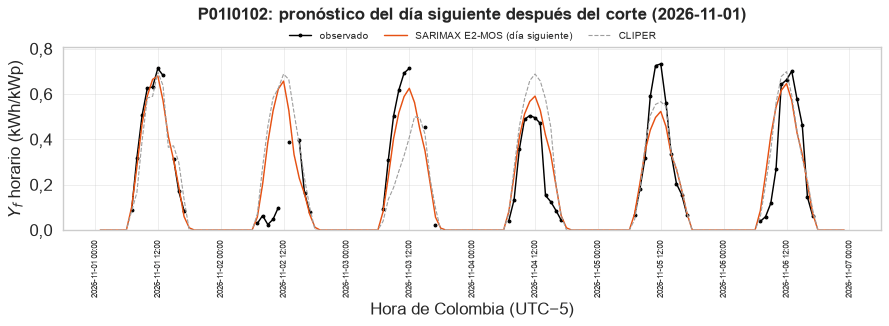

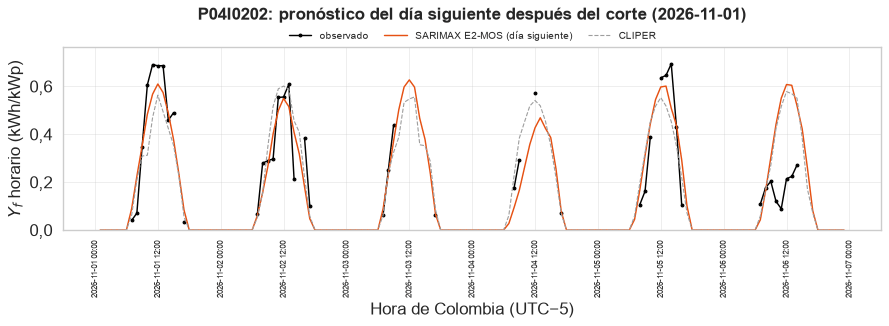

In [5]:
for codigo in [c.strip() for c in UNIDADES_FIGURA.split(",") if c.strip() in SALIDA]:
    grupo, horario, t30 = SALIDA[codigo]
    h = horario.copy()
    h.index = h.index.tz_convert(config.ZONA)
    # Un solo panel, el horario: el pronóstico a 30 días de la misma emisión esta en la figura del mes en curso del
    # cuaderno por localidad
    f, ax = plt.subplots(figsize=(11, 4.0))
    ax.plot(h.index, h["observado"], color="black", ls="-", lw=1.3, marker="o", ms=2.5, label="observado")   # con marcadores: se ven las horas aisladas
    ax.plot(h.index, h["pronostico"], color=config.COLOR_PRINCIPAL, ls="-", lw=1.3, label="SARIMAX E2-MOS (día siguiente)")
    ax.plot(h.index, h["cliper"], color="#9E9E9E", lw=1.0, ls="--", label="CLIPER")
    ax.set_ylim(0, 1.1 * np.nanmax(h[["observado", "pronostico", "cliper"]].to_numpy(dtype=float)))
    ax.set_ylabel("$Y_f$ horario (kWh/kWp)"); ax.legend(loc="upper center", ncol=3)
    ax.set_title(f"{codigo}: pronóstico del día siguiente después del corte ({CORTE})")
    fig(f, f"vivo_{codigo}", horario, escala_fechas=0.5)

## 4. Registro

In [6]:
ok = VIVO.dropna(subset=["nrmse_sarimax_pct"]) if "nrmse_sarimax_pct" in VIVO else VIVO.iloc[0:0]

def _mediana(col):
    v = ok[col].dropna() if col in ok else pd.Series(dtype=float)
    return round(float(v.median()), 4) if len(v) else None

RESUMEN_VIVO = {
    "unidades_operacion": int(len(UNIDADES)), "unidades_evaluables": int(len(ok)),
    "dias_observados": int((pd.Timestamp(FIN_OBS) - pd.Timestamp(CORTE)).days),
    "horas_mediana": _mediana("horas"),
    "nrmse_sarimax_mediana": _mediana("nrmse_sarimax_pct"), "nrmse_cliper_mediana": _mediana("nrmse_cliper_pct"),
    "skill_mediana": _mediana("skill_vs_cliper"),
    "supera_cliper": int((ok["skill_vs_cliper"] > 0).sum()) if len(ok) else 0,
    "cobertura_80_mediana": _mediana("cobertura_80"),
    "error_total_30d_abs_mediana": (round(float(ok["error_total_30d_pct"].abs().median()), 2)
                                    if len(ok) and ok["error_total_30d_pct"].notna().any() else None),
}
res.registrar("vivo", {"corte": CORTE, "observado_hasta": str((pd.Timestamp(FIN_OBS) - pd.Timedelta(days=1)).date()),
                       "resumen": RESUMEN_VIVO,
                       "unidades": VIVO.round(4).replace({np.nan: None}).to_dict(orient="index")})
display(Markdown(f"Resultados registrados en `vivo`: {RESUMEN_VIVO['unidades_evaluables']} unidades evaluables con "
                 f"{RESUMEN_VIVO['dias_observados']} días completos observados después del corte."))


Resultados registrados en `vivo`: 20 unidades evaluables con 6 días completos observados después del corte.